In [1]:
#imports
import scipy.sparse as sp
import numpy as np
import matplotlib.pyplot as plt

# This week:
<ul>
<li>1D heat matrix equation done
<li>Obtaining analysis of error and plotting the temperature distribution. 
</ul> 

In [2]:
def initial_condition(x, gL, gR, L):    # initial condition on [0, L]
    if gL == 1 and gR == 0:
        return np.cos(np.pi * x / (2 * L))
    c = 0.0 if (gL == 0 and gR == 0) else 1.0   # cosine coefficient
    return np.sin(np.pi * x / L) + c * np.cos(np.pi * x / L)

# Matrix Update Equation
$\mathbb{U}=\mathbb{B}\cdot\mathbb{U}+\vec{b}$</br></br>

$\mathbb{U}$: The temperature matrix. The initial condition gives the initial temperature distribution and it is updated accordingly. </br></br>
$\mathbb{B}$: The update matrix. This advances the solution by one timestep by the centered difference approximation in space, forward Euler in time.</br></br>
$\vec{b}$: The boundary condition vector. This represents the boundary condition for the PDE.



In [3]:
def solve_heat(kappa, gL, gR, exact, N=40, t_end=0.05, r=0.4, L=1.0, ic=None, bc="dirichlet"):
    # kappa  : diffusivity
    # gL, gR : boundary data at x=0 and x=L -- values u for Dirichlet,
    #          slopes u_x for Neumann
    # exact  : function exact(x, t) giving the exact solution at time t
    # N      : number of interior nodes
    # t_end  : final time
    # r      : diffusion number -- MUST be <= 0.5 for FTCS
    # L      : length of the interval [0, L]
    # ic     : function ic(x, gL, gR, L) giving the initial condition;
    #          defaults to initial_condition
    # bc     : "dirichlet" (fixed values) or "neumann" (fixed slopes)
    h      = L / (N + 1)                     # grid spacing
    x      = np.linspace(0.0, L, N + 2)
    if bc == "dirichlet":
        x  = x[1:-1]                         # interior nodes only
    M      = len(x)                          # number of unknowns
    dt     = r * h * h / kappa               # dt is DERIVED from r, not chosen
    nsteps = int(round(t_end / dt))

    if ic is None:
        ic = initial_condition
    U = ic(x, gL, gR, L)

    lower, upper = np.ones(M-1), np.ones(M-1)
    b = np.zeros(M)
    if bc == "dirichlet":
        b[0] = r*gL; b[-1] = r*gR
    else:                              # ghost points: u_{-1} = u_1 - 2h*gL, u_{M} = u_{M-2} + 2h*gR
        upper[0] = 2; lower[-1] = 2
        b[0] = -2*r*h*gL; b[-1] = 2*r*h*gR
    T = sp.diags([lower, -2*np.ones(M), upper], [-1, 0, 1], format="csc")
    B = (sp.identity(M, format="csc") + r*T).tocsc()

    times = [0.0]
    errs  = [0.0]                      # error at t=0 is zero: U is the exact IC

    for n in range(nsteps):
        U = B @ U + b
        times.append((n + 1) * dt)
        errs.append(np.max(np.abs(U - exact(x, (n + 1) * dt))))

    print(f"N = {N}, r = {r}, dt = {dt:.3e}, {nsteps} steps")
    print(f"max error = {np.max(np.abs(U - exact(x, nsteps * dt))):.3e}")

    return x, U, times, errs

# Testing
We need to solve some actual PDEs that have solutions. 
I will take some solved PDEs from the textbook <i>Basic Partial Differential Equations, Bleecker and Csordas</i> that have given analytical solutions. Then I will compare them to the numerical solution that is given by my code and find the maximum error obtained. 
</br>
</br>
Firstly, I will use the given pde 
$\newline DE:u_t=2u_{xx} 0\le x \le \pi,t\ge 0; \newline BC: u(0,t)=0, u(\pi,t)=0; \newline IC: u(x,0)=5\sin(2x)-30\sin(3x)$.</br></br>
By proposition 1 in Chapter 3.1 of this textbook, we have  
$\newline DE:u_t=ku_{xx} 0\le x \le L,t\ge 0; \newline BC: u(0,t)=0, u(L,t)=0; \newline IC: u(x,0)=\sum^{N}_{n=1} b_n\cdot\sin(\frac{n\pi x}{L}),\newline SOL'N: \sum^{N}_{n=1} b_ne^{-(n\cdot\pi/L)^2kt}\sin(\frac{n\pi x}{L})$
</br>
Hence, the given solution is equal to $u(x,t)=5e^{-8t}\sin(2x)-30e^{-18t}\sin(3x)$

Using this proposition, let us now validate solutions of this form with different coefficients.
We will report the error, as well as plot the temperature distribution along the "rod" for each test run.

k = 2.0, b_n = {2: 5, 3: -30}
N = 40, r = 0.4, dt = 1.174e-03, 43 steps
max error = 7.146e-02
<class 'numpy.ndarray'>

k = 1.0, b_n = {1: 1, 4: 2}
N = 40, r = 0.4, dt = 2.349e-03, 21 steps
max error = 7.975e-03
<class 'numpy.ndarray'>

k = 0.5, b_n = {1: 3, 2: -1, 5: 0.5}
N = 40, r = 0.4, dt = 4.697e-03, 11 steps
max error = 3.154e-03
<class 'numpy.ndarray'>

k = 2.0, b_n = {1: 10, 3: -4, 6: 1}
N = 40, r = 0.4, dt = 1.174e-03, 43 steps
max error = 1.068e-02
<class 'numpy.ndarray'>

k = 1.0, b_n = {1: 1}
N = 40, r = 0.4, dt = 2.349e-03, 21 steps
max error = 3.217e-05
<class 'numpy.ndarray'>

k = 3.0, b_n = {2: -7}
N = 40, r = 0.4, dt = 7.828e-04, 64 steps
max error = 6.340e-03
<class 'numpy.ndarray'>

k = 0.1, b_n = {1: 2, 3: 1, 7: -1}
N = 40, r = 0.4, dt = 2.349e-02, 2 steps
max error = 6.662e-03
<class 'numpy.ndarray'>

k = 1.5, b_n = {1: 4, 2: 3, 3: 2, 4: 1}
N = 40, r = 0.4, dt = 1.566e-03, 32 steps
max error = 9.607e-03
<class 'numpy.ndarray'>

k = 0.8, b_n = {5: 2, 8: -0.5}
N = 40,

/var/folders/wk/8vd029mj3mbgl94lf5r5m9080000gn/T/ipykernel_54201/1472289291.py:39: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize="small", loc="upper left", bbox_to_anchor=(1.02, 1))


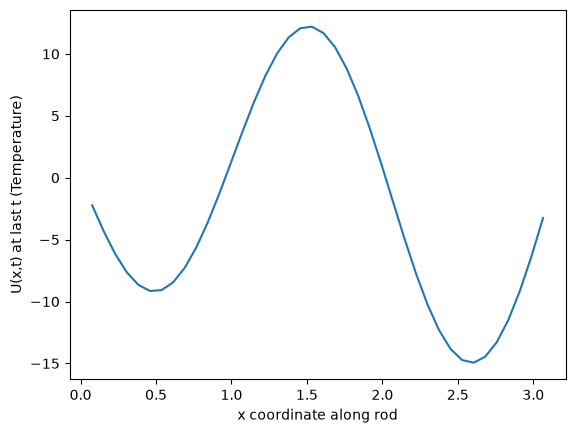

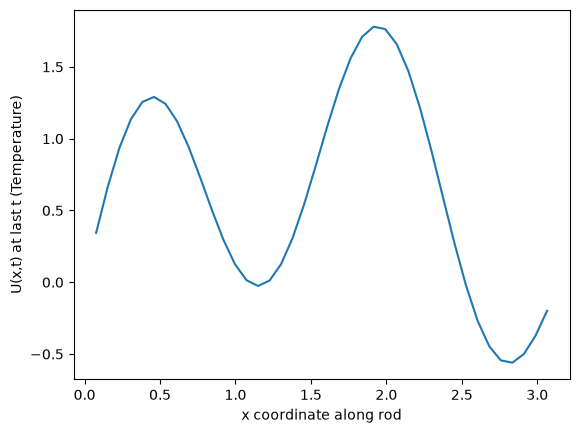

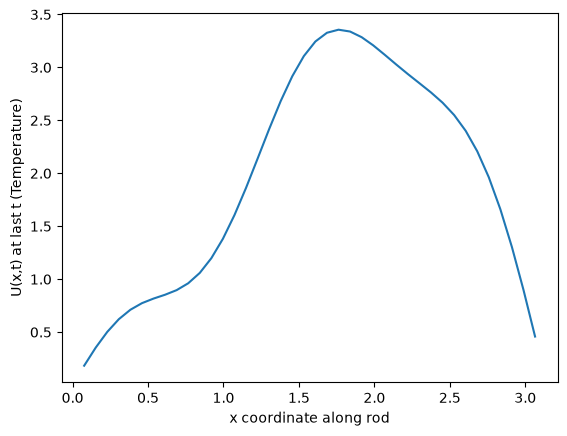

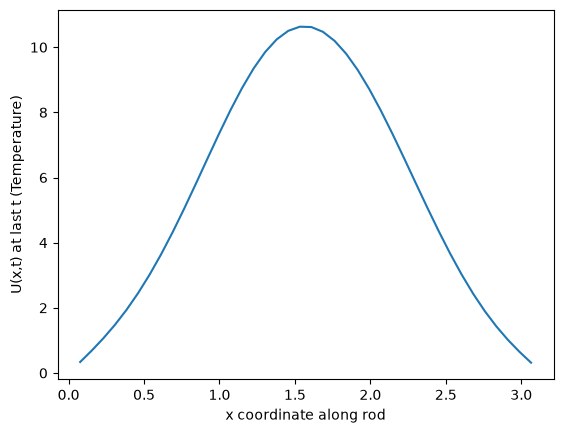

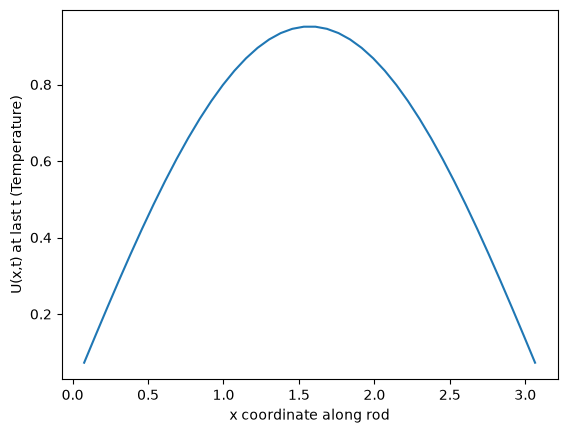

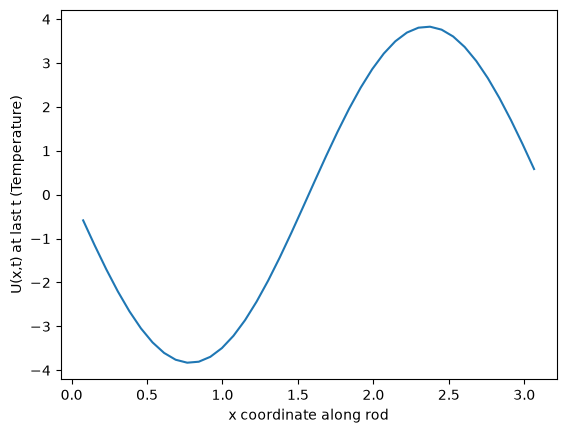

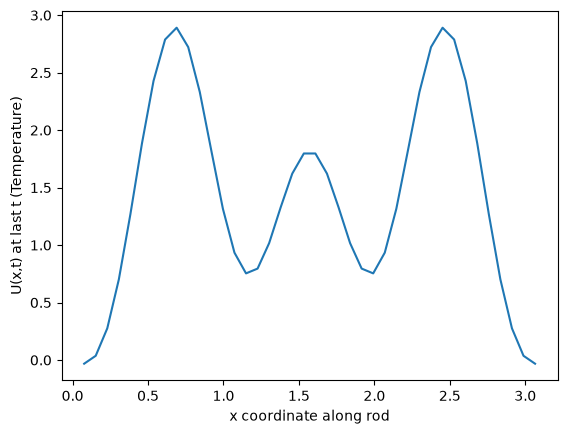

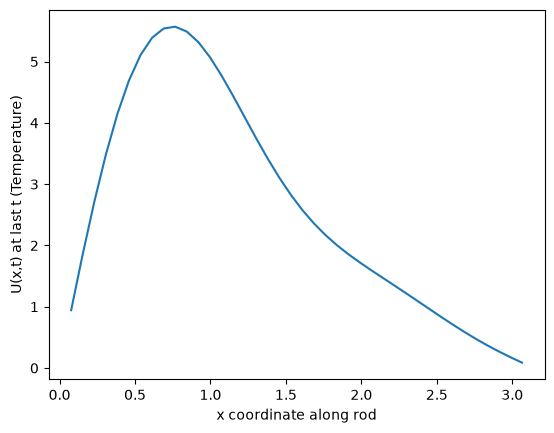

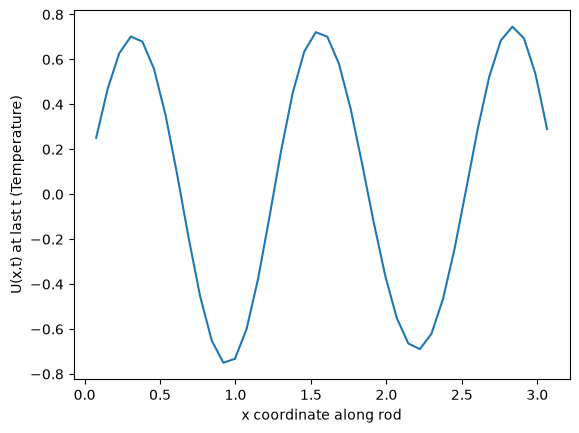

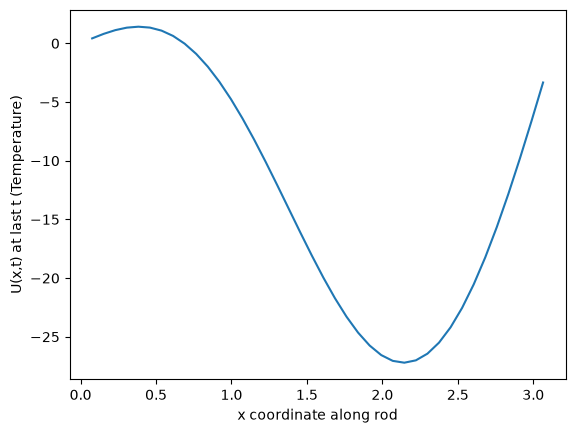

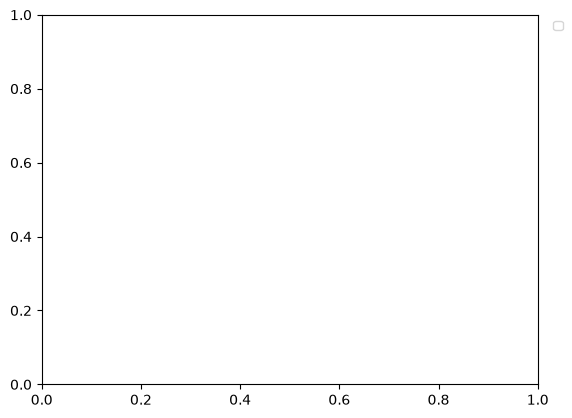

Mean: 0.014028856907100585, Median: 0.007776028181199046, Std. Dev: 0.019602490771976434


In [19]:
L = np.pi                               # interval [0, pi] for every run

def make_series(b, k, L):
    # b : dict {n: b_n} of sine coefficients
    # returns ic(x, gL, gR, L) = sum b_n sin(n pi x / L) and
    # exact(x, t) = sum b_n exp(-(n pi / L)^2 k t) sin(n pi x / L)
    def ic(x, gL, gR, L):
        return sum(bn * np.sin(n * np.pi * x / L) for n, bn in b.items())
    def exact(x, t):
        return sum(bn * np.exp(-(n * np.pi / L)**2 * k * t) * np.sin(n * np.pi * x / L)
                   for n, bn in b.items())
    return ic, exact

runs = [
    (2.0, {2: 5, 3: -30}),              # the example PDE above
    (1.0, {1: 1, 4: 2}),
    (0.5, {1: 3, 2: -1, 5: 0.5}),
    (2.0, {1: 10, 3: -4, 6: 1}),
    (1.0, {1: 1}),                      # single mode
    (3.0, {2: -7}),
    (0.1, {1: 2, 3: 1, 7: -1}),         # slow diffusion
    (1.5, {1: 4, 2: 3, 3: 2, 4: 1}),    # several consecutive modes
    (0.8, {5: 2, 8: -0.5}),             # higher modes only
    (1.0, {1: -20, 2: 15, 10: 0.2}),
]

max_errs = []
for k, b in runs:
    print(f"k = {k}, b_n = {b}")
    ic, exact = make_series(b, k, L)
    x_i, U_i, _, errs = solve_heat(k, 0.0, 0.0, exact, L=L, ic=ic)
    max_errs.append(errs[-1])      # max error at the final time
    print(type(U_i))
    plt.plot(x_i, U_i, label=f"k = {k}, b_n = {b}")
    plt.xlabel("x coordinate along rod")
    plt.ylabel("U(x,t) at last t (Temperature)")
    plt.figure()
    print()
plt.legend(fontsize="small", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()
max_errs = np.array(max_errs)
print(f"Mean: {np.mean(max_errs)}, Median: {np.median(max_errs)}, Std. Dev: {np.std(max_errs)}")


Now we will do an example in the cosine case. Similarly to above, the solution is obtained from the textbook.


N = 40, r = 0.4, dt = 2.349e-03, 21 steps
max error = 4.670e-04

k = 1.0, a_n = {1: 0.75, 3: 0.25}
N = 40, r = 0.4, dt = 2.349e-03, 21 steps
max error = 4.670e-04

k = 2.0, a_n = {0: 1, 2: 5, 3: -30}
N = 40, r = 0.4, dt = 1.174e-03, 43 steps
max error = 7.196e-02

k = 1.0, a_n = {0: 2, 1: 1}
N = 40, r = 0.4, dt = 2.349e-03, 21 steps
max error = 3.219e-05

k = 0.5, a_n = {1: 3, 2: -1, 5: 0.5}
N = 40, r = 0.4, dt = 4.697e-03, 11 steps
max error = 3.276e-03

k = 3.0, a_n = {2: -7}
N = 40, r = 0.4, dt = 7.828e-04, 64 steps
max error = 6.345e-03

k = 0.1, a_n = {0: -1, 1: 2, 3: 1, 7: -1}
N = 40, r = 0.4, dt = 2.349e-02, 2 steps
max error = 6.633e-03

k = 1.5, a_n = {1: 4, 2: 3, 3: 2, 4: 1}
N = 40, r = 0.4, dt = 1.566e-03, 32 steps
max error = 1.031e-02

k = 0.8, a_n = {5: 2, 8: -0.5}
N = 40, r = 0.4, dt = 2.936e-03, 17 steps
max error = 1.729e-02

k = 1.0, a_n = {0: 5, 1: -20, 2: 15, 10: 0.2}
N = 40, r = 0.4, dt = 2.349e-03, 21 steps
max error = 7.787e-03

Mean: 0.013788620258548372, Median

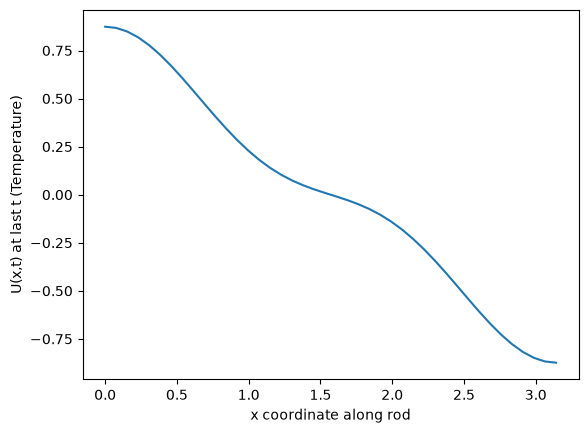

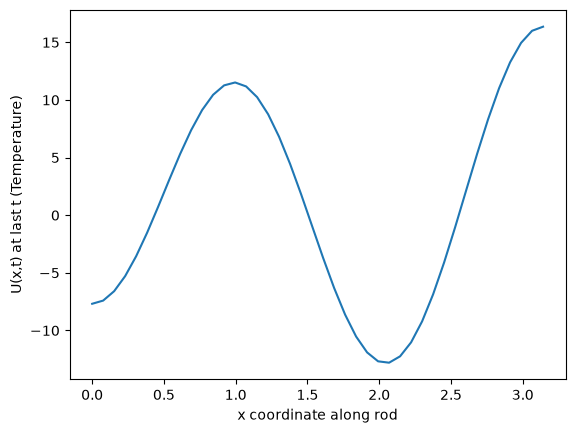

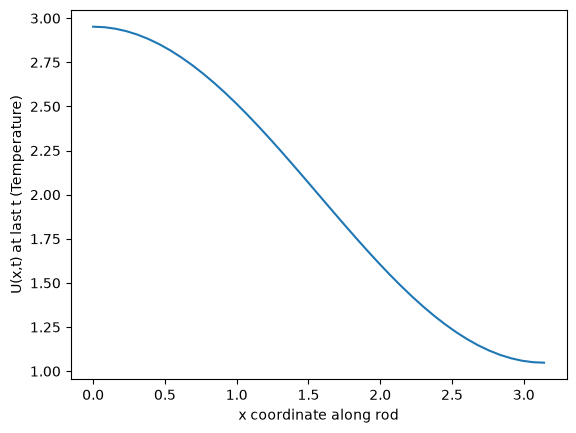

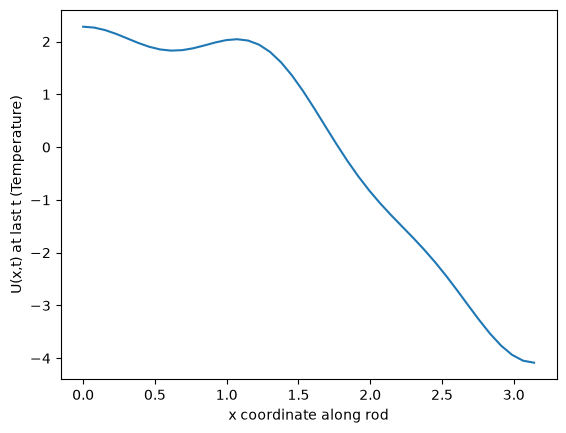

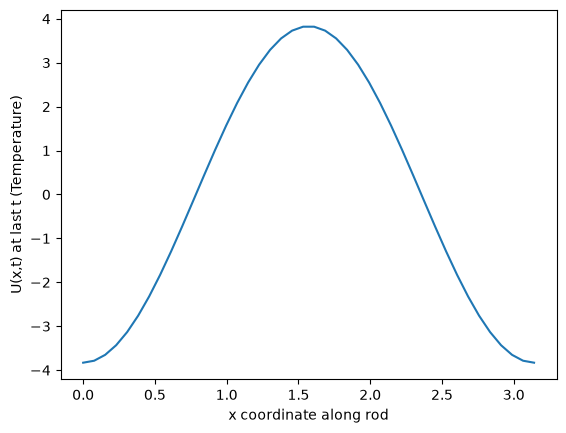

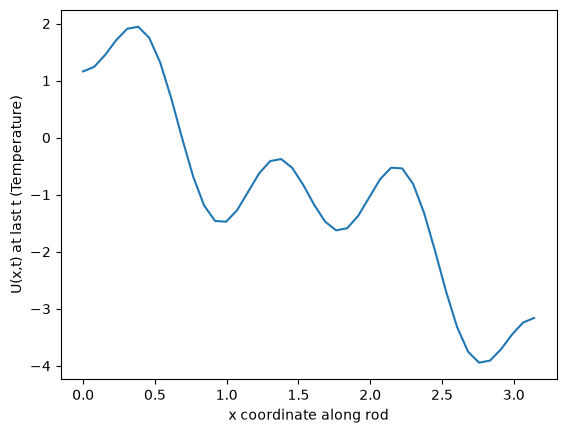

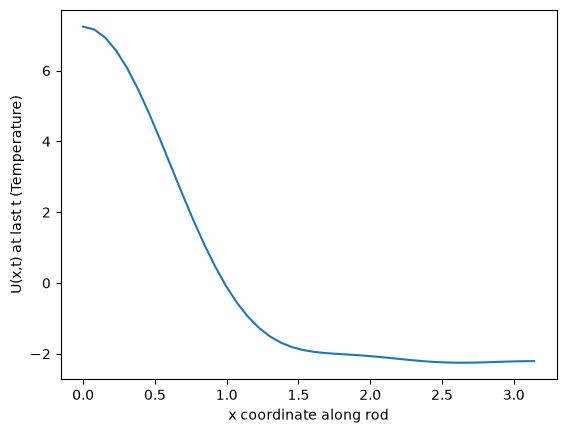

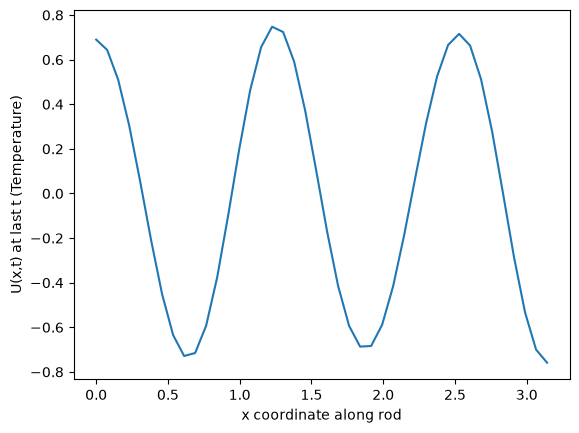

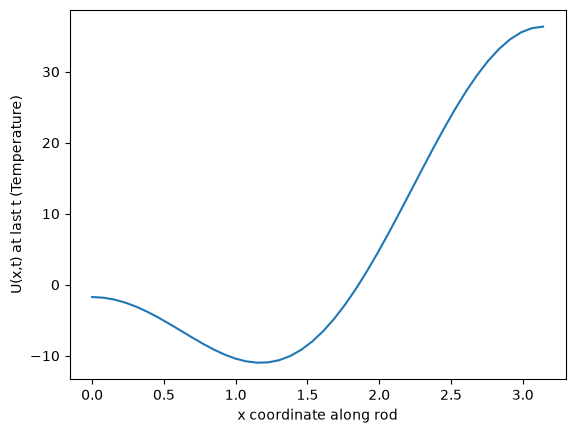

<Figure size 640x480 with 0 Axes>

In [20]:
def make_exact(x,t,k,L):
    return (3/4)*np.exp(-k*t*(np.pi/L)**(2))*np.cos(np.pi*x/L)+(1/4)*np.exp(-k*t*(3*np.pi/L)**2)*np.cos(3*np.pi*x/L)

k = 1.0
L = np.pi
exact = lambda x, t: make_exact(x, t, k, L)
ic    = lambda x, gL, gR, L: np.pow(np.cos(np.pi*x/L),3)
gL, gR = 0.0, 0.0                                         # insulated ends: u_x = 0
x, U, times, errs = solve_heat(k, gL, gR, exact, L=L, ic=ic, bc="neumann")
print()

def make_cos_series(a, k, L):
    # a : dict {n: a_n} of cosine coefficients (n = 0 is the constant term)
    # returns ic(x, gL, gR, L) = sum a_n cos(n pi x / L) and
    # exact(x, t) = sum a_n exp(-(n pi / L)^2 k t) cos(n pi x / L)
    def ic(x, gL, gR, L):
        return sum(an * np.cos(n * np.pi * x / L) for n, an in a.items())
    def exact(x, t):
        return sum(an * np.exp(-(n * np.pi / L)**2 * k * t) * np.cos(n * np.pi * x / L)
                   for n, an in a.items())
    return ic, exact

cos_runs = [
    (1.0, {1: 3/4, 3: 1/4}),            # the cos^3 example above
    (2.0, {0: 1, 2: 5, 3: -30}),
    (1.0, {0: 2, 1: 1}),                # constant plus single mode
    (0.5, {1: 3, 2: -1, 5: 0.5}),
    (3.0, {2: -7}),
    (0.1, {0: -1, 1: 2, 3: 1, 7: -1}),  # slow diffusion
    (1.5, {1: 4, 2: 3, 3: 2, 4: 1}),    # several consecutive modes
    (0.8, {5: 2, 8: -0.5}),             # higher modes only
    (1.0, {0: 5, 1: -20, 2: 15, 10: 0.2}),
]

max_errs = []
for k, a in cos_runs:
    print(f"k = {k}, a_n = {a}")
    ic, exact = make_cos_series(a, k, L)
    x_i, U_i, _, errs = solve_heat(k, 0.0, 0.0, exact, L=L, ic=ic, bc="neumann")
    plt.plot(x_i, U_i, label=f"k = {k}, b_n = {b}")
    plt.xlabel("x coordinate along rod")
    plt.ylabel("U(x,t) at last t (Temperature)")
    plt.figure()
    max_errs.append(errs[-1])      # max error at the final time
    print()
max_errs = np.array(max_errs)
print(f"Mean: {np.mean(max_errs)}, Median: {np.median(max_errs)}, Std. Dev: {np.std(max_errs)}")


# Future Work:
<ul>
<li>Make animations for each graph: analytical and fdtd on top of each other (same plot)
<li>Show the error along with the graph
<li>Implement this for 2 dimensions
<li>Work with nonhomogenous PDEs
<li>Write equations in terms of tau not k
<li> plot in terms of time.
<li>
</ul>

In [6]:
plt.plot(x,np.abs(U - exact(x, nsteps * dt)))
plt.title("Error wrt spatial position")
plt.xlabel("x")
plt.ylabel("Absolute error")
plt.show()

NameError: name 'nsteps' is not defined

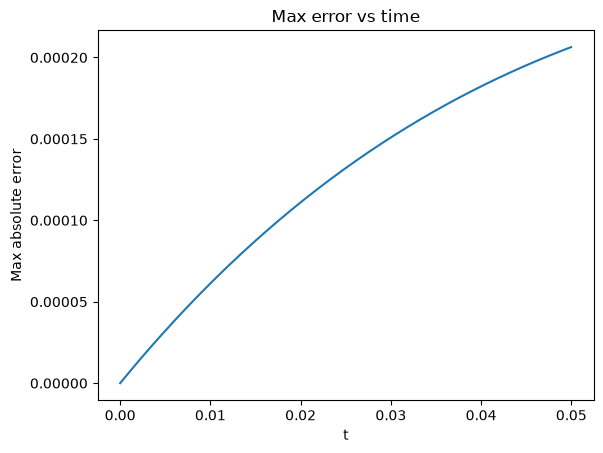

In [ ]:
plt.plot(times, errs)
plt.title("Max error vs time")
plt.xlabel("t")
plt.ylabel("Max absolute error")
plt.show()